# Module 4 – AdaBoost Analysis

## Parent–Young Adult Independence in the United States

### Objective

This notebook explores Adaptive Boosting (AdaBoost) for
forecasting the financial independence of youth.

The goals are to:

- Generate labeled training and test datasets.
- Perform one-hot encoding on categorical variables.
- Construct an AdaBoost classifier with decision stumps.
- Optimize the number of estimators and learning rate.
- Investigate validation accuracy through boosting iterations.
- Test the final classifier on unseen test data.
- Compare the results obtained by AdaBoost and Decision Tree
  classifier from Module 3.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from matplotlib.patches import FancyBboxPatch

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. AdaBoost Overview Visualizations

The visualizations below describe how the AdaBoost algorithm operates,
as well as how boosting is different from bagging.

In the bagging technique, the models learn independently through
resampling, while in boosting, models learn sequentially and pay attention to
the observations which have been wrongly classified before.

Decision stumps, re-weighted observations, weight of learners (alpha),
and weighted voting are shown in the visualizations below.

The visualizations below are just conceptual visualizations generated with
Python to explain the methodological procedure involved.

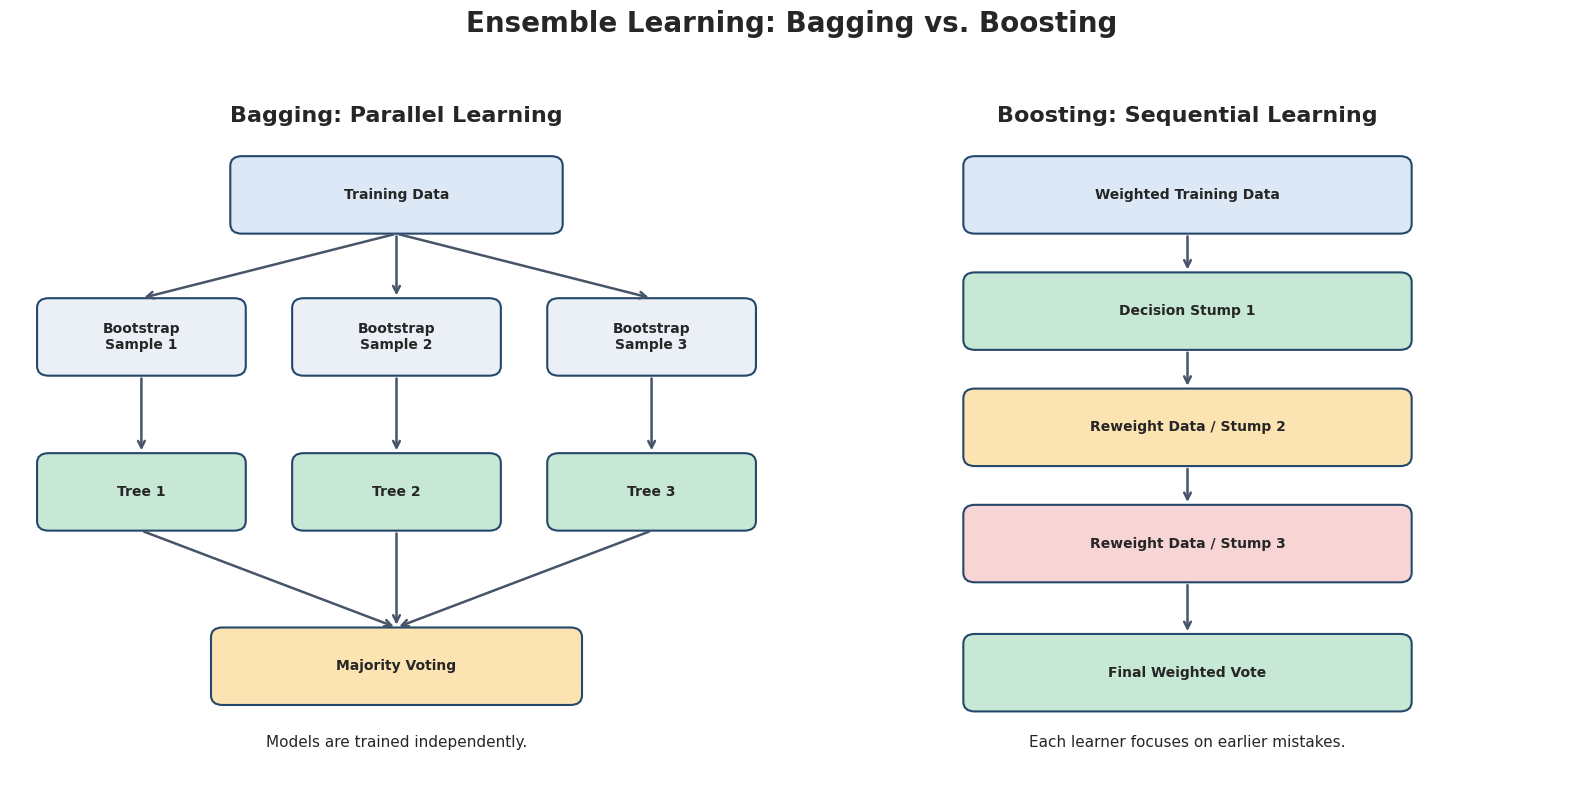

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

def draw_box(ax, x, y, text, color, width=0.24, height=0.09):

    box = FancyBboxPatch(
        (x - width / 2, y - height / 2),
        width,
        height,
        boxstyle="round,pad=0.015",
        facecolor=color,
        edgecolor="#24476B",
        linewidth=1.5
    )

    ax.add_patch(box)

    ax.text(
        x, y, text,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold"
    )


def draw_arrow(ax, x1, y1, x2, y2):

    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            color="#475569",
            lw=1.8
        )
    )


# BAGGING
ax = axes[0]

ax.set_title(
    "Bagging: Parallel Learning",
    fontsize=16,
    fontweight="bold"
)

draw_box(
    ax, 0.5, 0.90,
    "Training Data", "#DCE8F5", 0.4
)

for x, i in zip([0.17, 0.5, 0.83], [1, 2, 3]):

    draw_box(
        ax, x, 0.68,
        f"Bootstrap\nSample {i}", "#EAF0F6"
    )

    draw_arrow(ax, 0.5, 0.84, x, 0.74)

    draw_box(
        ax, x, 0.44,
        f"Tree {i}", "#C7E8D5"
    )

    draw_arrow(ax, x, 0.62, x, 0.50)
    draw_arrow(ax, x, 0.38, 0.5, 0.23)

draw_box(
    ax, 0.5, 0.17,
    "Majority Voting",
    "#FCE4B2", 0.45
)

ax.text(
    0.5, 0.045,
    "Models are trained independently.",
    ha="center", fontsize=11
)


# BOOSTING
ax = axes[1]

ax.set_title(
    "Boosting: Sequential Learning",
    fontsize=16,
    fontweight="bold"
)

positions = [
    (0.90, "Weighted Training Data", "#DCE8F5"),
    (0.72, "Decision Stump 1", "#C7E8D5"),
    (0.54, "Reweight Data / Stump 2", "#FCE4B2"),
    (0.36, "Reweight Data / Stump 3", "#F8D5D5"),
    (0.16, "Final Weighted Vote", "#C7E8D5")
]

for y, label, color in positions:

    draw_box(ax, 0.5, y, label, color, 0.55)

for i in range(len(positions) - 1):

    draw_arrow(
        ax,
        0.5, positions[i][0] - 0.06,
        0.5, positions[i + 1][0] + 0.06
    )

ax.text(
    0.5, 0.045,
    "Each learner focuses on earlier mistakes.",
    ha="center", fontsize=11
)

for ax in axes:

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

fig.suptitle(
    "Ensemble Learning: Bagging vs. Boosting",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.94])

plt.savefig(
    "adaboost_bagging_vs_boosting.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

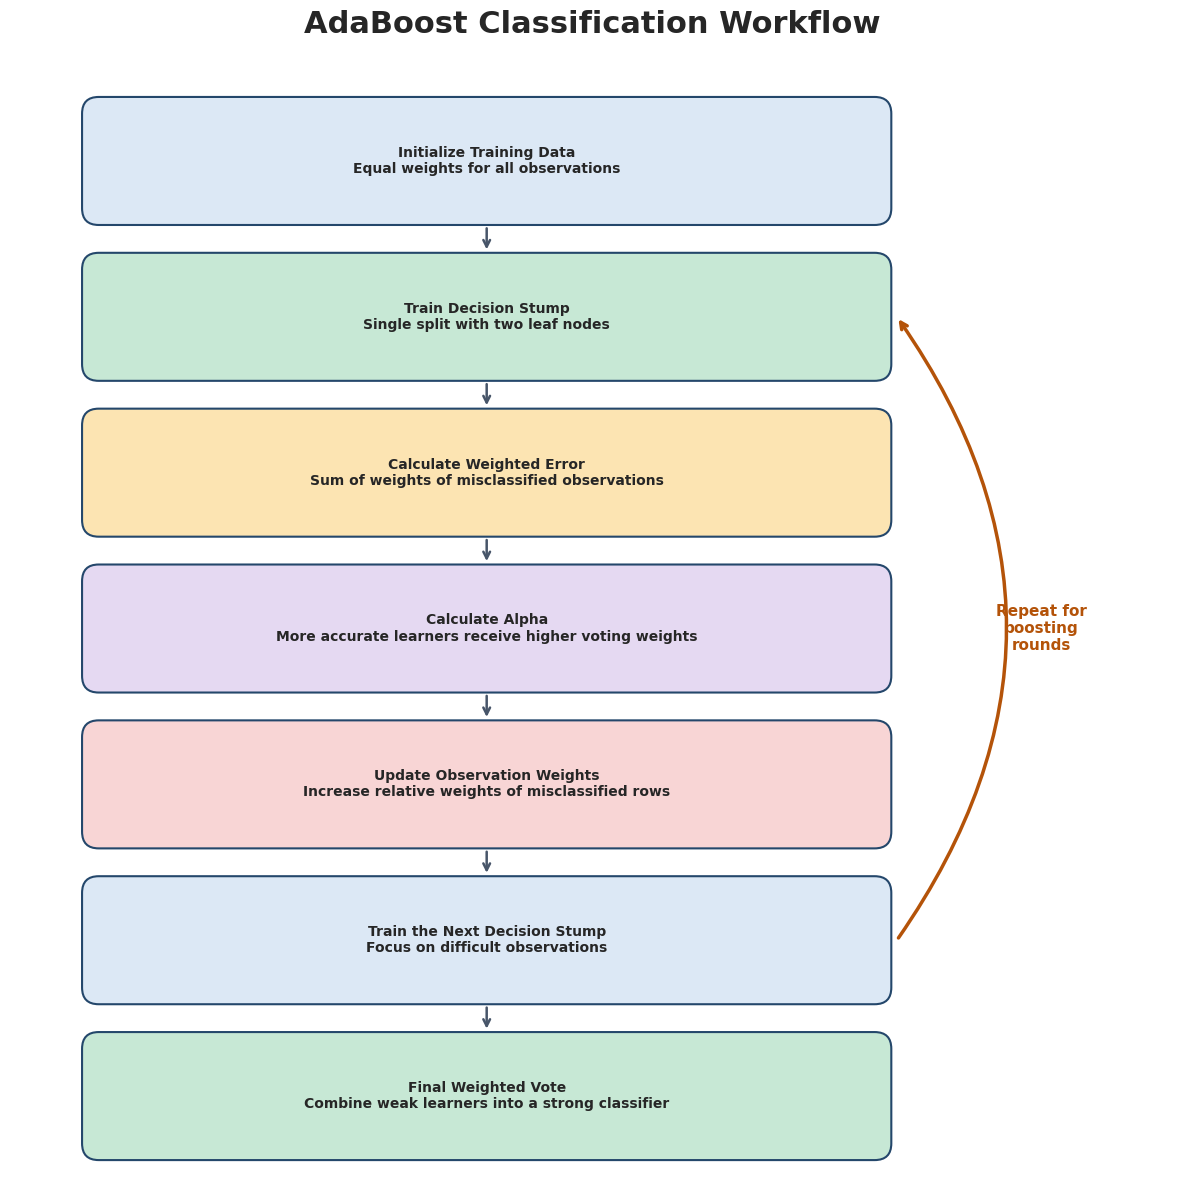

In [4]:
fig, ax = plt.subplots(figsize=(12, 12))

steps = [
    (0.91, "Initialize Training Data\nEqual weights for all observations", "#DCE8F5"),

    (0.77, "Train Decision Stump\nSingle split with two leaf nodes", "#C7E8D5"),

    (0.63, "Calculate Weighted Error\nSum of weights of misclassified observations", "#FCE4B2"),

    (0.49, "Calculate Alpha\nMore accurate learners receive higher voting weights", "#E5D9F2"),

    (0.35, "Update Observation Weights\nIncrease relative weights of misclassified rows", "#F8D5D5"),

    (0.21, "Train the Next Decision Stump\nFocus on difficult observations", "#DCE8F5"),

    (0.07, "Final Weighted Vote\nCombine weak learners into a strong classifier", "#C7E8D5")
]

# Draw workflow boxes
for y, label, color in steps:

    draw_box(
        ax,
        0.43,
        y,
        label,
        color,
        width=0.70,
        height=0.085
    )

# Connect workflow steps
for i in range(len(steps) - 1):

    draw_arrow(
        ax,
        0.43,
        steps[i][0] - 0.058,
        0.43,
        steps[i + 1][0] + 0.058
    )

# Add repeated boosting loop
ax.annotate(
    "",
    xy=(0.80, 0.77),
    xytext=(0.80, 0.21),
    arrowprops=dict(
        arrowstyle="->",
        connectionstyle="arc3,rad=0.35",
        color="#B45309",
        linewidth=2.5
    )
)

ax.text(
    0.93,
    0.49,
    "Repeat for\nboosting\nrounds",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    color="#B45309"
)

ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1)
ax.axis("off")

plt.title(
    "AdaBoost Classification Workflow",
    fontsize=22,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

plt.savefig(
    "adaboost_workflow.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 2. Data Loading and Inspection

The labelled dataset from Module 3 is used again for
AdaBoost classification.

The labelled dataset consists of 1,478 records and six predictor
variables, all corresponding to demographic and socio-economic
factors.

Prior to implementing AdaBoost model, the data needs to be checked
for its dimensions, column names, data types, presence of missing
values and target class distribution.

As in the case of Regression, the same target class labels and
training-test split proportions will be used for all classification
models.

In [5]:

base_url = "https://raw.githubusercontent.com/swejal22/parent-child-independence-project/main/"

df_ada = pd.read_csv(base_url + "nb_labeled_data.csv")


print("Dataset shape:", df_ada.shape)

print("\nColumn Names:")
print(df_ada.columns.tolist())


print("\nData Types:")
print(df_ada.dtypes)


print("\nMissing Values:")
print(df_ada.isnull().sum())


print("\nFinancial Independence Distribution:")
print(
    df_ada["financial_independence"]
    .value_counts()
    .sort_index()
)


print("\nDataset Preview:")
display(df_ada.head())

Dataset shape: (1478, 7)

Column Names:
['received_financial_help', 'lives_with_parents', 'parent_involvement_level', 'communication_satisfaction', 'employment_status', 'age_group', 'financial_independence']

Data Types:
received_financial_help       float64
lives_with_parents            float64
parent_involvement_level      float64
communication_satisfaction    float64
employment_status             float64
age_group                       int64
financial_independence        float64
dtype: object

Missing Values:
received_financial_help       0
lives_with_parents            0
parent_involvement_level      0
communication_satisfaction    0
employment_status             0
age_group                     0
financial_independence        0
dtype: int64

Financial Independence Distribution:
financial_independence
1.0    786
2.0    338
3.0    163
4.0    117
5.0     74
Name: count, dtype: int64

Dataset Preview:


,received_financial_help,lives_with_parents,parent_involvement_level,communication_satisfaction,employment_status,age_group,financial_independence
0,1.0,1.0,1.0,3.0,2.0,1,2.0
1,2.0,3.0,3.0,3.0,1.0,1,1.0
2,2.0,3.0,3.0,3.0,2.0,2,1.0
3,2.0,3.0,3.0,2.0,1.0,1,4.0
4,1.0,3.0,3.0,1.0,1.0,2,2.0


## 3. Binary Target Variable Preparation

Financial independence is represented by five
response levels in the original financial
independence variable.

In the case of the AdaBoost classifier, these
levels are grouped into two categories:

- Category 1: Financially completely or mostly
independent.
- Category 0: Financially somewhat, a little,
or not at all independent.

This target classification is identical to that of
the logistic regression model estimated earlier in
Module 4.

The original financial independence variable is
dropped from the predictors to avoid data leakage.

Class balance will also be assessed for possible
class imbalance problem.

In [6]:

assert df_ada["financial_independence"].isin(
    [1, 2, 3, 4, 5]
).all()


df_ada["independence_binary"] = (
    df_ada["financial_independence"] <= 2
).astype(int)

print("Dataset shape:", df_ada.shape)


print("\nBinary Target Distribution:")
print(
    df_ada["independence_binary"]
    .value_counts()
    .sort_index()
)


print("\nClass Proportions (%):")
print(
    df_ada["independence_binary"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nPrepared Dataset Preview:")
display(df_ada.head())

Dataset shape: (1478, 8)

Binary Target Distribution:
independence_binary
0     354
1    1124
Name: count, dtype: int64

Class Proportions (%):
independence_binary
0    23.951286
1    76.048714
Name: proportion, dtype: float64

Prepared Dataset Preview:


,received_financial_help,lives_with_parents,parent_involvement_level,communication_satisfaction,employment_status,age_group,financial_independence,independence_binary
0,1.0,1.0,1.0,3.0,2.0,1,2.0,1
1,2.0,3.0,3.0,3.0,1.0,1,1.0,1
2,2.0,3.0,3.0,3.0,2.0,2,1.0,1
3,2.0,3.0,3.0,2.0,1.0,1,4.0,0
4,1.0,3.0,3.0,1.0,1.0,2,2.0,1


## 4. Feature Selection and Train-Test Split

Six predictor variables will be chosen for the AdaBoost classification model:

- Received financial support
- Living situation with parents
- Parents' level of involvement
- Satisfactory communication
- Working situation
- Age category

The financial independence binary variable will be
used as the target variable.

The data set will be split into 80% training data
and 20% testing data through stratified sampling
with a random state of 42, as in the case of the
Regression analysis.

The training and testing data sets will be mutually
exclusive in order to prevent data leakage.

The hyperparameters tuning will be done through
cross-validation on the training data set only.

In [7]:
# Select the six predictor variables
features = [
    "received_financial_help",
    "lives_with_parents",
    "parent_involvement_level",
    "communication_satisfaction",
    "employment_status",
    "age_group"
]

X = df_ada[features].copy()
y = df_ada["independence_binary"].copy()

# Create the same split as Regression
train_idx, test_idx = train_test_split(
    df_ada.index,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create training and testing sets
X_train = X.loc[train_idx].copy()
X_test = X.loc[test_idx].copy()

y_train = y.loc[train_idx].copy()
y_test = y.loc[test_idx].copy()

# Verify that the datasets are disjoint
overlap = set(train_idx).intersection(set(test_idx))

assert len(overlap) == 0

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("Overlapping observations:", len(overlap))

# Verify class distributions
print("\nTraining Class Distribution (%):")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Class Distribution (%):")
print(y_test.value_counts(normalize=True) * 100)

# Display dataset samples
print("\nTraining Dataset Sample:")
display(X_train.head())

print("\nTesting Dataset Sample:")
display(X_test.head())

Training set shape: (1182, 6)
Testing set shape: (296, 6)
Overlapping observations: 0

Training Class Distribution (%):
independence_binary
1    76.05753
0    23.94247
Name: proportion, dtype: float64

Testing Class Distribution (%):
independence_binary
1    76.013514
0    23.986486
Name: proportion, dtype: float64

Training Dataset Sample:


,received_financial_help,lives_with_parents,parent_involvement_level,communication_satisfaction,employment_status,age_group
74,1.0,3.0,3.0,3.0,2.0,1
1058,1.0,3.0,3.0,1.0,1.0,2
243,2.0,3.0,3.0,3.0,1.0,2
261,2.0,3.0,3.0,3.0,1.0,2
528,2.0,3.0,3.0,3.0,1.0,2



Testing Dataset Sample:


,received_financial_help,lives_with_parents,parent_involvement_level,communication_satisfaction,employment_status,age_group
1057,1.0,3.0,2.0,3.0,3.0,2
164,2.0,3.0,1.0,1.0,2.0,2
806,1.0,1.0,3.0,3.0,3.0,1
43,2.0,3.0,3.0,3.0,1.0,2
1093,2.0,2.0,3.0,3.0,3.0,1


## 5. Categorical Feature Encoding

The six predictor variables are denoted by survey codes.
These codes are categorical in nature rather than numerical measures.

Categorical predictors will be one hot encoded to make
them compatible with the AdaBoost algorithm.

All the categories will be kept as decision stumps do
not require eliminating reference category predictors due to
problems of multicollinearity.

Fitting the encoder will only be done on the training
set while applying the encoder to the testing set will just be
for documentation purposes.

For hyperparameter tuning, the preprocessing steps will be included
inside a machine learning pipeline such that the encoder will be fitted
on a different fold during cross-validation training.

This process will help to prevent information leakage from validation
and test observations.

In [8]:

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)


X_train_encoded = encoder.fit_transform(X_train)


X_test_encoded = encoder.transform(X_test)


encoded_features = encoder.get_feature_names_out(features)


X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=encoded_features,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=encoded_features,
    index=X_test.index
)


print("Original training shape:", X_train.shape)
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)


print("\nEncoded Feature Names:")
print(encoded_features.tolist())


print("\nEncoded Training Dataset:")
display(X_train_encoded.head())

print("\nEncoded Testing Dataset:")
display(X_test_encoded.head())

Original training shape: (1182, 6)
Encoded training shape: (1182, 18)
Encoded testing shape: (296, 18)

Encoded Feature Names:
['received_financial_help_1.0', 'received_financial_help_2.0', 'lives_with_parents_1.0', 'lives_with_parents_2.0', 'lives_with_parents_3.0', 'parent_involvement_level_1.0', 'parent_involvement_level_2.0', 'parent_involvement_level_3.0', 'communication_satisfaction_1.0', 'communication_satisfaction_2.0', 'communication_satisfaction_3.0', 'employment_status_1.0', 'employment_status_2.0', 'employment_status_3.0', 'employment_status_4.0', 'employment_status_5.0', 'age_group_1', 'age_group_2']

Encoded Training Dataset:


,received_financial_help_1.0,received_financial_help_2.0,lives_with_parents_1.0,lives_with_parents_2.0,lives_with_parents_3.0,parent_involvement_level_1.0,parent_involvement_level_2.0,parent_involvement_level_3.0,communication_satisfaction_1.0,communication_satisfaction_2.0,communication_satisfaction_3.0,employment_status_1.0,employment_status_2.0,employment_status_3.0,employment_status_4.0,employment_status_5.0,age_group_1,age_group_2
74,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1058,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
243,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
261,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
528,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0



Encoded Testing Dataset:


,received_financial_help_1.0,received_financial_help_2.0,lives_with_parents_1.0,lives_with_parents_2.0,lives_with_parents_3.0,parent_involvement_level_1.0,parent_involvement_level_2.0,parent_involvement_level_3.0,communication_satisfaction_1.0,communication_satisfaction_2.0,communication_satisfaction_3.0,employment_status_1.0,employment_status_2.0,employment_status_3.0,employment_status_4.0,employment_status_5.0,age_group_1,age_group_2
1057,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
164,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
806,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
43,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1093,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


## 6. Saving Prepared Datasets

The prepared labeled dataset, training dataset,
testing dataset, and one-hot encoding dataset are
exported as CSV files for documentation and
reproducibility purposes.

All the exported datasets include the binary
target of financial independence.

The original target of financial independence is
removed from the dataset to avoid target
leakage.

The exported datasets will be provided on the
AdaBoost website page to showcase the data
preparation steps.

In [9]:

adaboost_data = df_ada[
    features + ["independence_binary"]
].copy()


adaboost_train = adaboost_data.loc[train_idx].copy()
adaboost_test = adaboost_data.loc[test_idx].copy()


encoded_train = X_train_encoded.copy()
encoded_train["independence_binary"] = y_train


encoded_test = X_test_encoded.copy()
encoded_test["independence_binary"] = y_test


adaboost_data.to_csv(
    "adaboost_labeled_data.csv", index=False
)

adaboost_train.to_csv(
    "adaboost_training_data.csv", index=False
)

adaboost_test.to_csv(
    "adaboost_testing_data.csv", index=False
)

encoded_train.to_csv(
    "adaboost_encoded_training_data.csv", index=False
)

encoded_test.to_csv(
    "adaboost_encoded_testing_data.csv", index=False
)

print("All AdaBoost datasets saved successfully!")

print("\nComplete dataset:", adaboost_data.shape)
print("Training dataset:", adaboost_train.shape)
print("Testing dataset:", adaboost_test.shape)
print("Encoded training dataset:", encoded_train.shape)
print("Encoded testing dataset:", encoded_test.shape)

All AdaBoost datasets saved successfully!

Complete dataset: (1478, 7)
Training dataset: (1182, 7)
Testing dataset: (296, 7)
Encoded training dataset: (1182, 19)
Encoded testing dataset: (296, 19)


## 7. Data Preparation Visualizations

Images of the labeled data set, training data set,
and test data set have been created using Python.

These images highlight the structure of the prepared
data sets, which consist of six initial predictors and
a binary variable of financial independence target.

Before and after images encoding are also created to
highlight how the six categorical predictors get
converted to eighteen binary predictor variables.

All the data preparation images have been created
using the actual data sets used in this analysis.

In [10]:
def save_table_image(data, title, filename, n_rows=6):

    sample = data.head(n_rows).copy()


    sample.columns = [
        col.replace("_", "\n")
        for col in sample.columns
    ]

    fig, ax = plt.subplots(
        figsize=(max(14, len(sample.columns) * 2), 4.5)
    )

    ax.axis("off")


    table = ax.table(
        cellText=sample.values,
        colLabels=sample.columns,
        cellLoc="center",
        loc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 2.8)


    for (row, col), cell in table.get_celld().items():

        cell.set_edgecolor("#D1D5DB")

        if row == 0:
            cell.set_facecolor("#24476B")
            cell.set_text_props(
                color="white",
                weight="bold"
            )
            cell.set_height(cell.get_height() * 1.5)

        elif row % 2 == 0:
            cell.set_facecolor("#EAF0F6")

        else:
            cell.set_facecolor("#FFFFFF")


    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold",
        pad=20
    )

    plt.tight_layout()


    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

print("Table visualization function created successfully!")

Table visualization function created successfully!


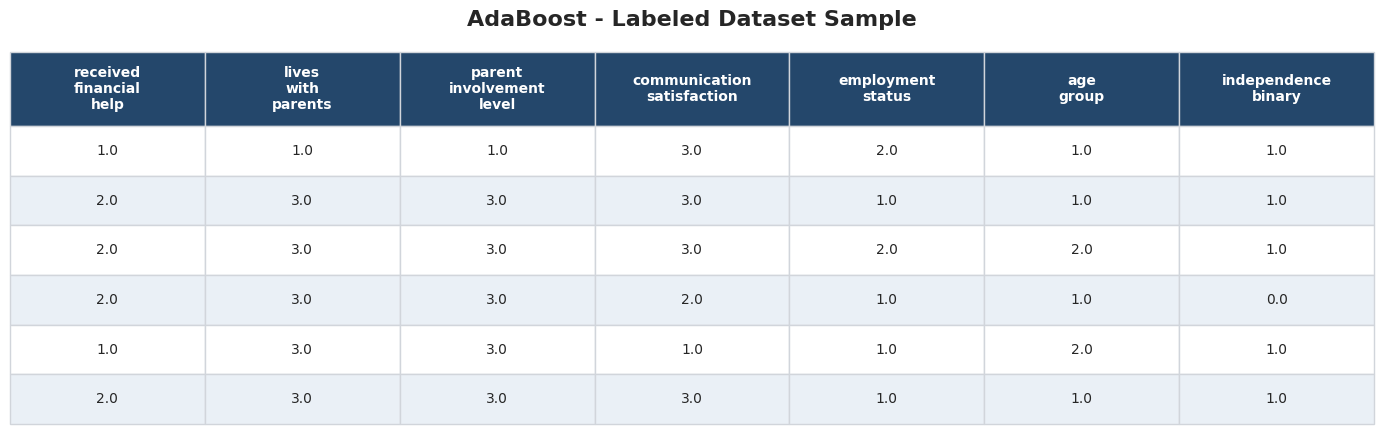

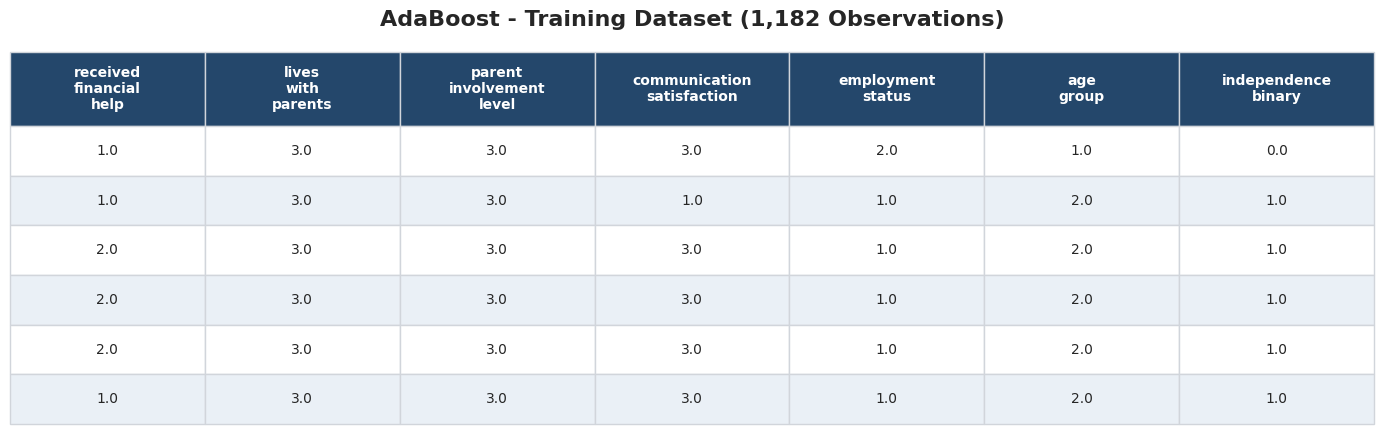

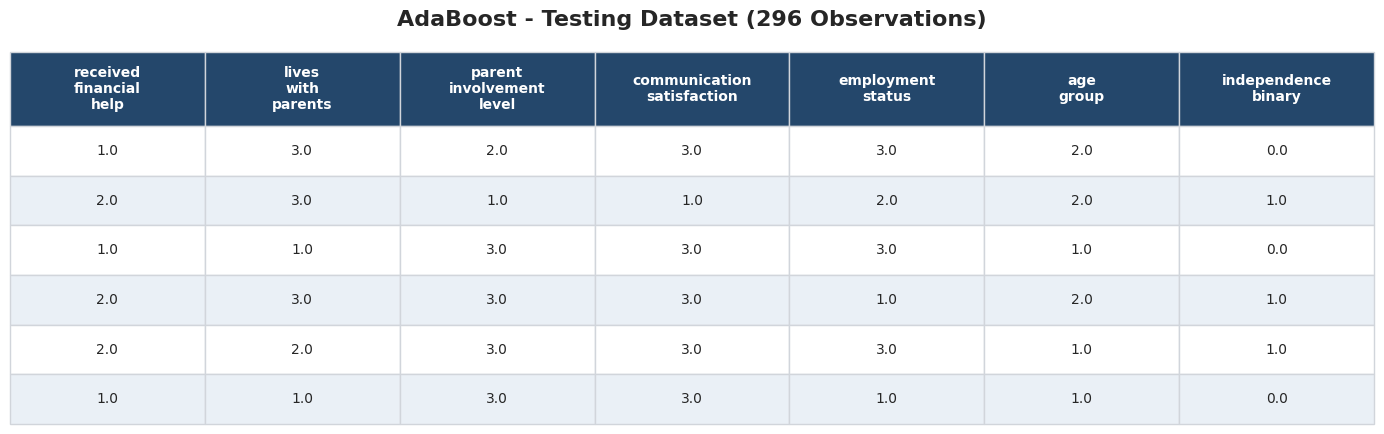

In [11]:
# Image 1: Complete labeled dataset
save_table_image(
    adaboost_data,
    "AdaBoost - Labeled Dataset Sample",
    "adaboost_labeled_sample.png"
)

# Image 2: Training dataset
save_table_image(
    adaboost_train,
    "AdaBoost - Training Dataset (1,182 Observations)",
    "adaboost_training_sample.png"
)

# Image 3: Testing dataset
save_table_image(
    adaboost_test,
    "AdaBoost - Testing Dataset (296 Observations)",
    "adaboost_testing_sample.png"
)

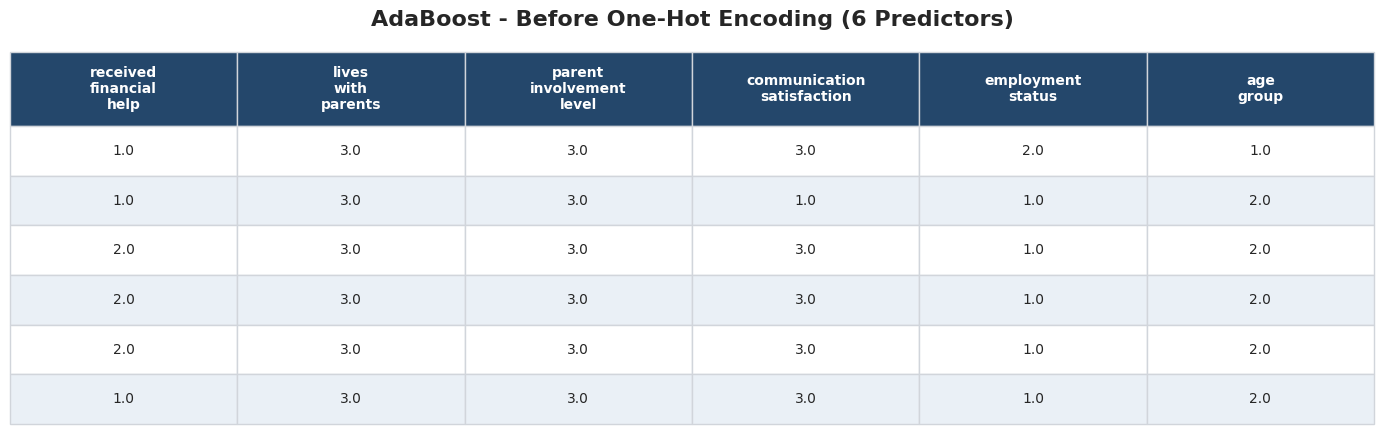

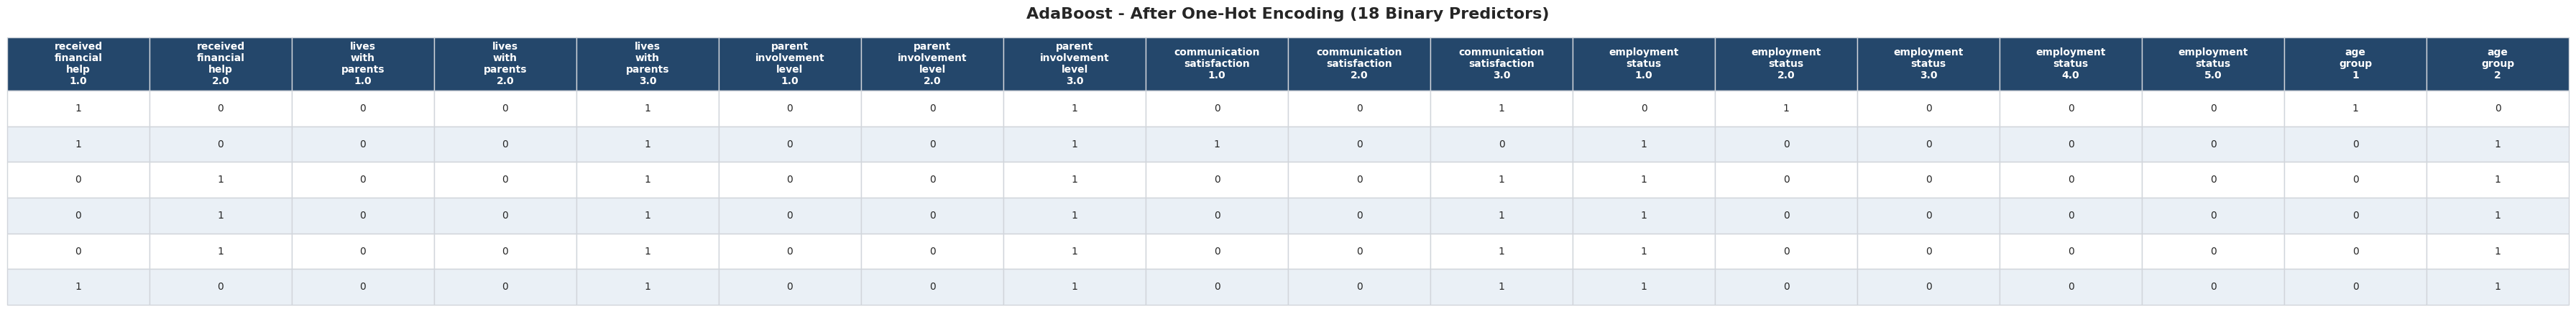

In [12]:
# Image 4: Before one-hot encoding
save_table_image(
    X_train,
    "AdaBoost - Before One-Hot Encoding (6 Predictors)",
    "adaboost_before_encoding.png"
)

# Image 5: After one-hot encoding
save_table_image(
    X_train_encoded.astype(int),
    "AdaBoost - After One-Hot Encoding (18 Binary Predictors)",
    "adaboost_after_encoding.png"
)

In [13]:
# Verify all generated AdaBoost files
adaboost_files = sorted([
    filename
    for filename in os.listdir(".")
    if filename.startswith("adaboost_")
    and filename.endswith((".csv", ".png"))
])

print("Generated AdaBoost Files:\n")

for i, filename in enumerate(adaboost_files, 1):
    print(f"{i}. {filename}")

print(f"\nTotal files: {len(adaboost_files)}")

Generated AdaBoost Files:

1. adaboost_after_encoding.png
2. adaboost_bagging_vs_boosting.png
3. adaboost_before_encoding.png
4. adaboost_encoded_testing_data.csv
5. adaboost_encoded_training_data.csv
6. adaboost_labeled_data.csv
7. adaboost_labeled_sample.png
8. adaboost_testing_data.csv
9. adaboost_testing_sample.png
10. adaboost_training_data.csv
11. adaboost_training_sample.png
12. adaboost_workflow.png

Total files: 12


## 8. AdaBoost Classification Model

AdaBoost technique is used to classify young adults
whether they have high or lower financial independence.

Weak learners are decision trees that have a maximum
depth of one called decision stumps.

Initially, the AdaBoost model with 50 estimators and
learning rate 1.0 is generated.

A machine learning pipeline is used for preprocessing,
which consists of one-hot encoding followed by the
AdaBoost classifier.

The above model is initially evaluated with 5-fold
stratified cross-validation using the training dataset.

Further, hyperparameters are tuned to find the
appropriate estimators and learning rate.

Finally, testing dataset remains separately until the
model selection process.

In [14]:
from sklearn.model_selection import cross_val_score


stump = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)


ada_model = AdaBoostClassifier(
    estimator=stump,
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)


ada_pipeline = Pipeline([
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )),
    ("classifier", ada_model)
])


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


ada_cv_scores = cross_val_score(
    ada_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)


ada_pipeline.fit(X_train, y_train)


print("Initial AdaBoost Model Results")
print("=" * 45)

for i, score in enumerate(ada_cv_scores, 1):
    print(f"Fold {i} Accuracy: {score * 100:.2f}%")

print(f"\nMean Validation Accuracy: {ada_cv_scores.mean() * 100:.2f}%")

print(f"Standard Deviation: {ada_cv_scores.std() * 100:.2f} percentage points")

print("\nInitial Model Parameters:")
print("Decision Tree Maximum Depth: 1")
print("Number of Estimators: 50")
print("Learning Rate: 1.0")

print("\nInitial AdaBoost model trained successfully!")

Initial AdaBoost Model Results
Fold 1 Accuracy: 83.97%
Fold 2 Accuracy: 83.97%
Fold 3 Accuracy: 87.29%
Fold 4 Accuracy: 83.05%
Fold 5 Accuracy: 84.75%

Mean Validation Accuracy: 84.60%
Standard Deviation: 1.45 percentage points

Initial Model Parameters:
Decision Tree Maximum Depth: 1
Number of Estimators: 50
Learning Rate: 1.0

Initial AdaBoost model trained successfully!


## 9. AdaBoost Hyperparameter Tuning

Hyperparameter tuning is conducted in order to determine the
set of parameters that yields the best mean validation accuracy.

The two most significant AdaBoost hyperparameters are:

- n_estimators: Maximum number of weak classifiers
  in the ensemble.
- learning_rate: Determines the influence of each
  weak classifier on the final model.

A five-fold stratified cross-validation method with
the help of GridSearchCV is utilized in order to
determine optimal values of these parameters.

One-hot encoding is included in the pipeline in order to
avoid any information leakage across training and
validation folds.

The best parameter set is chosen according to the mean
accuracy across cross-validation. Final testing data is not
included in the hyperparameter selection process.

In [15]:

param_grid = {
    "classifier__n_estimators": [
        10, 25, 50, 75, 100, 150, 200
    ],
    "classifier__learning_rate": [
        0.01, 0.05, 0.1, 0.5, 1.0
    ]
}


grid_search = GridSearchCV(
    estimator=ada_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    return_train_score=True,
    refit=True
)


grid_search.fit(X_train, y_train)


best_ada_model = grid_search.best_estimator_

best_n_estimators = grid_search.best_params_[
    "classifier__n_estimators"
]

best_learning_rate = grid_search.best_params_[
    "classifier__learning_rate"
]

best_cv_accuracy = grid_search.best_score_


print("AdaBoost Hyperparameter Tuning Results")
print("=" * 50)

print("Best Number of Estimators:", best_n_estimators)
print("Best Learning Rate:", best_learning_rate)

print(f"Best Validation Accuracy: {best_cv_accuracy * 100:.2f}%")

print(f"Initial Validation Accuracy: {ada_cv_scores.mean() * 100:.2f}%")

print(
    f"Validation Accuracy Improvement: "
    f"{(best_cv_accuracy - ada_cv_scores.mean()) * 100:.2f} "
    "percentage points"
)


ada_tuning_results = pd.DataFrame(
    grid_search.cv_results_
)

ada_tuning_results.to_csv(
    "adaboost_hyperparameter_results.csv",
    index=False
)


print("\nTop 10 Hyperparameter Combinations:")

display(
    ada_tuning_results[[
        "param_classifier__n_estimators",
        "param_classifier__learning_rate",
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]].sort_values("rank_test_score").head(10)
)

AdaBoost Hyperparameter Tuning Results
Best Number of Estimators: 200
Best Learning Rate: 0.5
Best Validation Accuracy: 85.03%
Initial Validation Accuracy: 84.60%
Validation Accuracy Improvement: 0.42 percentage points

Top 10 Hyperparameter Combinations:


,param_classifier__n_estimators,param_classifier__learning_rate,mean_train_score,mean_test_score,std_test_score,rank_test_score
27,200,0.50,0.851313,0.850261,0.012648,1
26,150,0.50,0.851102,0.849414,0.013753,2
22,25,0.50,0.848350,0.848570,0.013935,3
23,50,0.50,0.851524,0.848566,0.014968,4
25,100,0.50,0.851313,0.848566,0.014968,4
12,150,0.05,0.847504,0.847726,0.014316,6
17,75,0.10,0.847504,0.847726,0.014316,6
13,200,0.05,0.847081,0.847726,0.014316,6
18,100,0.10,0.847081,0.847726,0.014316,6
34,200,1.00,0.849831,0.847726,0.015750,6


### Hyperparameter Tuning Results

All 35 combinations of hyperparameters were
tested using 5-fold stratified cross-validation.

The most successful combination of parameters was:

- Number of estimators: 200
- Learning rate: 0.5
- Maximum depth of decision trees: 1
- Average validation accuracy: 85.03%

For the initial AdaBoost model, the average validation
accuracy was 84.60%. The hyperparameter optimization increased
the validation accuracy for approximately 0.42%, computed on
unrounded values.

The result implies that adding a large number of weak learners with
moderate learning rate may be useful to increase classification performance.

However, the increase is relatively low, and there
were several other parameter sets which provided similar validation
accuracies.

The current combination is the best model from all tested configurations,
and not a guaranteed optimal one.

The testing data set for final model testing
has not been used for any AdaBoost models selection or validation.

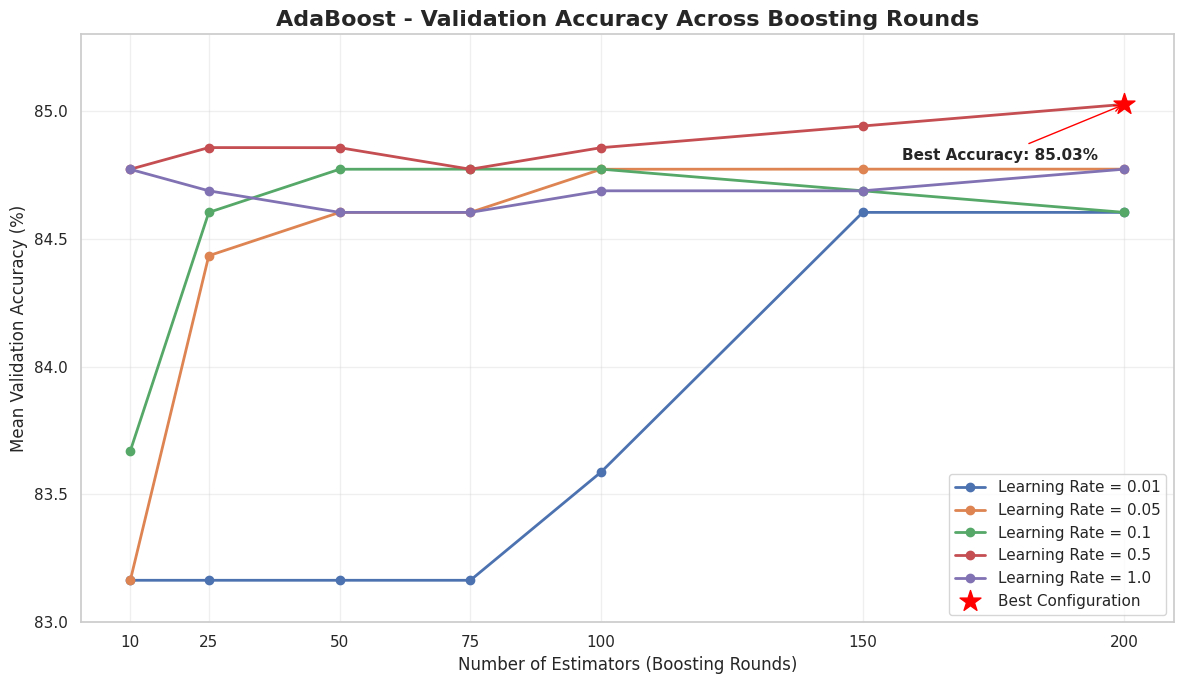

In [16]:
# Generate validation accuracy plot
plt.figure(figsize=(12, 7))

learning_rates = [0.01, 0.05, 0.1, 0.5, 1.0]

for rate in learning_rates:

    subset = ada_tuning_results[
        ada_tuning_results[
            "param_classifier__learning_rate"
        ] == rate
    ].sort_values("param_classifier__n_estimators")

    plt.plot(
        subset["param_classifier__n_estimators"],
        subset["mean_test_score"] * 100,
        marker="o",
        linewidth=2,
        markersize=6,
        label=f"Learning Rate = {rate}"
    )

# Highlight the best parameter combination
plt.scatter(
    best_n_estimators,
    best_cv_accuracy * 100,
    color="red",
    marker="*",
    s=250,
    zorder=5,
    label="Best Configuration"
)

plt.annotate(
    f"Best Accuracy: {best_cv_accuracy * 100:.2f}%",
    xy=(best_n_estimators, best_cv_accuracy * 100),
    xytext=(-160, -40),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="red"),
    fontsize=11,
    fontweight="bold"
)

plt.title(
    "AdaBoost - Validation Accuracy Across Boosting Rounds",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Number of Estimators (Boosting Rounds)", fontsize=12)
plt.ylabel("Mean Validation Accuracy (%)", fontsize=12)

plt.xticks([10, 25, 50, 75, 100, 150, 200])
plt.ylim(83.0, 85.3)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "adaboost_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Validation Accuracy Across Boosting Rounds

The plot below demonstrates the behavior of AdaBoost
with varying amounts of estimators and learning rates.

The learning rate of 0.01 is slow to progress
and needs more boosting rounds to produce
a decent level of accuracy.

The learning rates of 0.05 and 0.1 have an initial
progression, followed by leveling off or even
decreasing.

The learning rate of 1.0 creates small jumps in
validation accuracy depending on the amount of
additional estimators.

The learning rate of 0.5 has produced the best
mean validation accuracy at 85.03% using
200 estimators.

From this set of experiments, it can be concluded
that an increase in the number of estimators does
not guarantee better classification performance.
Additionally, the learning rate impacts the
model's ability to learn.

Based on the results above, the final classifier
will have 200 estimators and the learning rate of
0.5.

## 10. Final AdaBoost Model Evaluation

Selected AdaBoost model via GridSearchCV
uses 200 estimators with a learning rate of 0.5.

Refitted model has been trained on the entire
dataset consisting of 1,182 records.

The model is being evaluated by the unseen test
dataset consisting of 296 observations.

The metrics for the evaluation are:

- Test Accuracy
- Confusion Matrix
- Precision
- Recall
- F1 Score

Majority class baseline has also been computed since
the target class financial independence is imbalanced.

The test results would help in identifying how well
AdaBoost works in detecting young adults who have
high and lower financial independence.

In [17]:

y_ada_pred = best_ada_model.predict(X_test)


ada_accuracy = accuracy_score(
    y_test,
    y_ada_pred
)


ada_cm = confusion_matrix(
    y_test,
    y_ada_pred,
    labels=[0, 1]
)


majority_class = y_train.mode()[0]

baseline_predictions = np.full(
    len(y_test),
    majority_class
)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)


print("Final AdaBoost Model Results")
print("=" * 50)

print("Number of Estimators:", best_n_estimators)
print("Learning Rate:", best_learning_rate)

print(f"\nBest Validation Accuracy: {best_cv_accuracy * 100:.2f}%")
print(f"Test Accuracy: {ada_accuracy * 100:.2f}%")
print(f"Majority-Class Baseline: {baseline_accuracy * 100:.2f}%")

print(
    f"Improvement Over Baseline: "
    f"{(ada_accuracy - baseline_accuracy) * 100:.2f} "
    "percentage points"
)

print("\nConfusion Matrix:")
print(ada_cm)

print("\nCorrect Predictions:", np.trace(ada_cm))
print("Incorrect Predictions:", ada_cm.sum() - np.trace(ada_cm))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_ada_pred,
    labels=[0, 1],
    target_names=[
        "Lower Independence",
        "High Independence"
    ],
    zero_division=0
))

Final AdaBoost Model Results
Number of Estimators: 200
Learning Rate: 0.5

Best Validation Accuracy: 85.03%
Test Accuracy: 87.16%
Majority-Class Baseline: 76.01%
Improvement Over Baseline: 11.15 percentage points

Confusion Matrix:
[[ 46  25]
 [ 13 212]]

Correct Predictions: 258
Incorrect Predictions: 38

Classification Report:
                    precision    recall  f1-score   support

Lower Independence       0.78      0.65      0.71        71
 High Independence       0.89      0.94      0.92       225

          accuracy                           0.87       296
         macro avg       0.84      0.80      0.81       296
      weighted avg       0.87      0.87      0.87       296



### Final AdaBoost Classification Results

The tuned AdaBoost model had an accuracy of
87.16%, correctly classifying 258 out of 296 testing

observations.

In comparison to the majority class baseline of
76.01%, the model had performed around 11.15
percentage points better.

From the confusion matrix, we can see that there
were 46 individuals having lower financial
independence and 212 individuals with high
financial independence which were correctly
predicted by the model.

On the other hand, 25 individuals having lower
financial independence were falsely predicted to
have high financial independence and 13
individuals having high financial independence were
incorrectly predicted to have lower financial
independence.

The model was able to give a recall rate of
approximately 65% for lower financial independence
and 94% for high financial independence.

This suggests that AdaBoost performs better when it
comes to identifying respondents with high financial
independence.

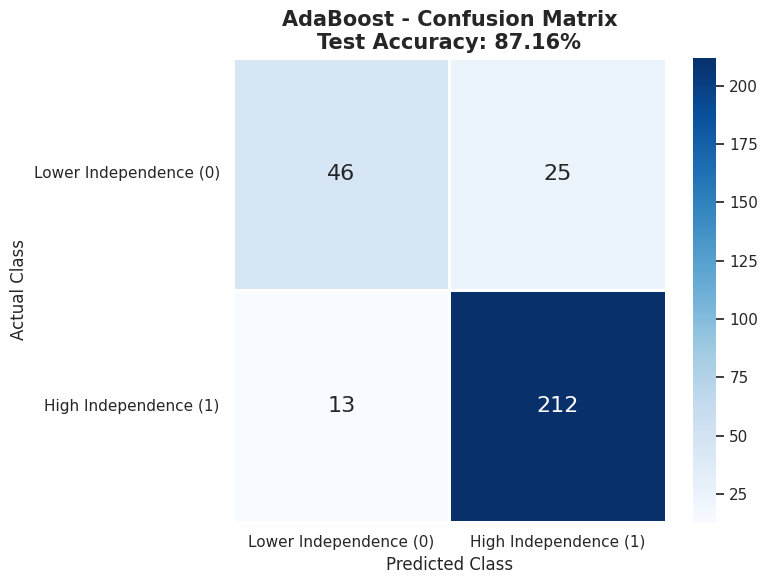

In [18]:
# Generate AdaBoost confusion matrix visualization
plt.figure(figsize=(8, 6))

sns.heatmap(
    ada_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    xticklabels=[
        "Lower Independence (0)",
        "High Independence (1)"
    ],
    yticklabels=[
        "Lower Independence (0)",
        "High Independence (1)"
    ],
    annot_kws={"size": 16}
)

plt.title(
    f"AdaBoost - Confusion Matrix\n"
    f"Test Accuracy: {ada_accuracy * 100:.2f}%",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "adaboost_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Comparison with Decision Tree from Module 3

In Module 3, three Decision Tree models were created
to predict the financial independence into five categories.

The most effective Decision Tree was built based on
the Gini criterion and a maximum depth of five,
with an accuracy rate of 59.12% in the test dataset.

An AdaBoost classifier created in Module 4 has
an accuracy rate of 87.16% in the test data.
However, these results cannot be compared since the
original Decision Tree classifier predicts five
categories, while AdaBoost predicts only two.

To perform a more appropriate comparison, the best
Decision Tree model is rebuilt based on the same
target variable, predictors, one-hot encoding method,
and training and test data sets as AdaBoost.

The original Gini criterion, maximum depth of five,
and random state 42 are kept.

The two classifiers are compared in terms of their
testing accuracy and classification performance.

In [19]:
# Recreate the best Decision Tree from Module 3
binary_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)


tree_pipeline = Pipeline([
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )),
    ("classifier", binary_tree)
])


tree_pipeline.fit(X_train, y_train)


y_tree_pred = tree_pipeline.predict(X_test)


tree_accuracy = accuracy_score(
    y_test,
    y_tree_pred
)


tree_cm = confusion_matrix(
    y_test,
    y_tree_pred,
    labels=[0, 1]
)


accuracy_difference = (
    ada_accuracy - tree_accuracy
) * 100

print("Decision Tree vs. AdaBoost")
print("=" * 45)

print(f"Decision Tree Accuracy: {tree_accuracy * 100:.2f}%")
print(f"AdaBoost Accuracy: {ada_accuracy * 100:.2f}%")

print(
    f"Accuracy Difference (AdaBoost - Tree): "
    f"{accuracy_difference:+.2f} percentage points"
)

print("\nDecision Tree Confusion Matrix:")
print(tree_cm)

print("\nDecision Tree Classification Report:")
print(classification_report(
    y_test,
    y_tree_pred,
    labels=[0, 1],
    target_names=[
        "Lower Independence",
        "High Independence"
    ],
    zero_division=0
))

Decision Tree vs. AdaBoost
Decision Tree Accuracy: 85.14%
AdaBoost Accuracy: 87.16%
Accuracy Difference (AdaBoost - Tree): +2.03 percentage points

Decision Tree Confusion Matrix:
[[ 41  30]
 [ 14 211]]

Decision Tree Classification Report:
                    precision    recall  f1-score   support

Lower Independence       0.75      0.58      0.65        71
 High Independence       0.88      0.94      0.91       225

          accuracy                           0.85       296
         macro avg       0.81      0.76      0.78       296
      weighted avg       0.84      0.85      0.84       296



### Decision Tree and AdaBoost Comparison Results

Decision Tree classifier had an accuracy of 85.14%,
while the tuned AdaBoost classifier had an accuracy of 87.16%.

AdaBoost classifier performed slightly better by
around 2.03%. It had a total of 258 correct classifications
in the test set, while the Decision Tree classifier had
252 correct classifications.

In addition, AdaBoost had a higher recall for financially independent respondents,
by 7% as compared to Decision Tree, which had a recall of 58%.

Recall for highly financially independent respondents was
approximately 94% for both classifiers.

From these results, it is evident that using many weak decision stumps in
combination with the AdaBoost algorithm performs better than
the depth five Decision Tree for classification of financial independence.

But these are only associations.

Decision Tree vs. AdaBoost Comparison:


,Model,Accuracy,Accuracy_Percent
0,Decision Tree,0.8514,85.1351
1,AdaBoost,0.8716,87.1622


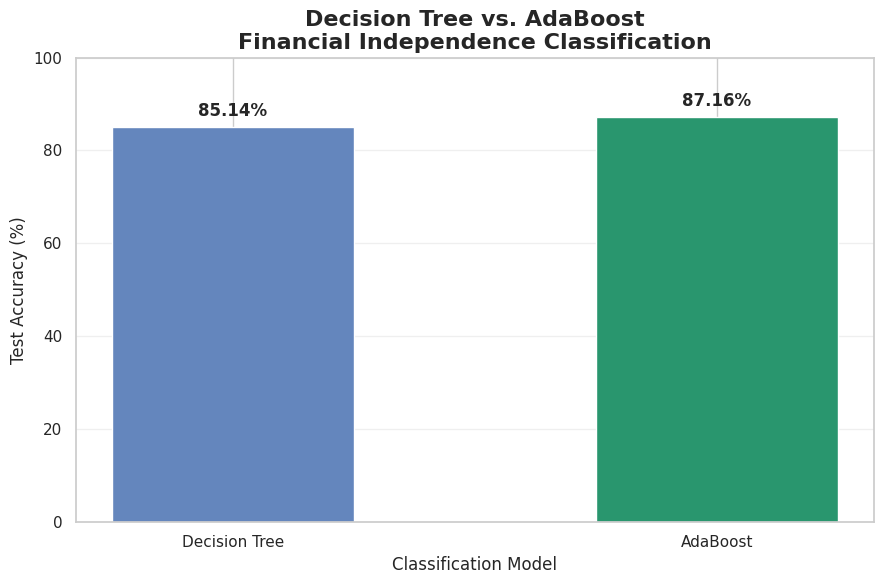


AdaBoost improvement: 2.03 percentage points


In [20]:

adaboost_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "AdaBoost"
    ],
    "Accuracy": [
        tree_accuracy,
        ada_accuracy
    ]
})


adaboost_comparison["Accuracy_Percent"] = (
    adaboost_comparison["Accuracy"] * 100
)


print("Decision Tree vs. AdaBoost Comparison:")
display(adaboost_comparison.round(4))


adaboost_comparison.to_csv(
    "adaboost_model_comparison.csv",
    index=False
)


fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    adaboost_comparison["Model"],
    adaboost_comparison["Accuracy_Percent"],
    color=["#6486BD", "#29966E"],
    width=0.5
)


ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=5,
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    "Decision Tree vs. AdaBoost\n"
    "Financial Independence Classification",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel("Test Accuracy (%)", fontsize=12)
ax.set_xlabel("Classification Model", fontsize=12)

ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()


plt.savefig(
    "adaboost_model_comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(
    f"\nAdaBoost improvement: "
    f"{(ada_accuracy - tree_accuracy) * 100:.2f} percentage points"
)

## 12. AdaBoost Conclusions

In this analysis, it is analyzed whether AdaBoost could
predict the financial independence of young adults in
the United States through socioeconomic,
demographic, and familial factors.

It was found that the best AdaBoost
implementation had a testing accuracy of 87.16% or
a total of 258 correct predictions out of 296
observations. It was better than the baseline value of
76.01%, meaning that the classifier had learned more
than just predicting the majority class.

Hyperparameter tuning indicated that 200 estimators
and a learning rate of 0.5 yielded the highest mean
cross-validation accuracy of 85.03%.

In comparison with the binary Decision Tree
classifier that had an accuracy of 85.14%, AdaBoost
performed better with an improvement of about 2.03
percentage points.

The results also showed some differences between
the two categories. AdaBoost classified almost all
respondents with high financial independence
correctly while 65% of those with lower financial
independence were correctly classified.

It may be concluded that the use of AdaBoost
classifier can enhance classification performance
when compared to one Decision Tree.

Nevertheless, the study has some limitations.
The original five categories of financial independence
were reduced to two classes, thus losing some
information. Moreover, the sample suffers from
an imbalanced target distribution, with about 76%
of respondents falling into the high-independence
category.

Furthermore, the models do not use survey weights,
and their outcomes only reflect predictive
relationships rather than causal relationships.
Hence, the results of the research cannot be
interpreted as nationally representative estimates.

In general, AdaBoost produced a moderate improvement
in classification and proved the efficiency
of the ensemble approach for exploring patterns
related to financial independence of young people.

In [21]:
# Save final AdaBoost evaluation metrics

adaboost_metrics = pd.DataFrame({
    "Model": [
        "Initial AdaBoost",
        "Tuned AdaBoost",
        "Tuned AdaBoost",
        "Majority-Class Baseline",
        "Binary Decision Tree",
        "Tuned AdaBoost vs. Decision Tree"
    ],
    "Metric": [
        "Mean CV Accuracy",
        "Best Mean CV Accuracy",
        "Test Accuracy",
        "Test Accuracy",
        "Test Accuracy",
        "Accuracy Improvement (percentage points)"
    ],
    "Value": [
        ada_cv_scores.mean(),
        best_cv_accuracy,
        ada_accuracy,
        baseline_accuracy,
        tree_accuracy,
        (ada_accuracy - tree_accuracy) * 100
    ]
})

print("Final AdaBoost Evaluation Metrics:")
display(adaboost_metrics.round(4))

# Save results to CSV
adaboost_metrics.to_csv(
    "adaboost_evaluation_metrics.csv",
    index=False
)

print("\nFinal AdaBoost evaluation metrics saved successfully!")

Final AdaBoost Evaluation Metrics:


,Model,Metric,Value
0,Initial AdaBoost,Mean CV Accuracy,0.8460
1,Tuned AdaBoost,Best Mean CV Accuracy,0.8503
2,Tuned AdaBoost,Test Accuracy,0.8716
3,Majority-Class Baseline,Test Accuracy,0.7601
4,Binary Decision Tree,Test Accuracy,0.8514
5,Tuned AdaBoost vs. Decision Tree,Accuracy Improvement (percentage points),2.0270



Final AdaBoost evaluation metrics saved successfully!


In [22]:
# Verify all generated AdaBoost CSV and PNG files

adaboost_files = sorted([
    filename
    for filename in os.listdir(".")
    if filename.startswith("adaboost_")
    and filename.endswith((".csv", ".png"))
])

print("Final AdaBoost Generated Files:")
print("=" * 45)

for i, filename in enumerate(adaboost_files, 1):
    print(f"{i}. {filename}")

csv_files = [
    f for f in adaboost_files if f.endswith(".csv")
]

png_files = [
    f for f in adaboost_files if f.endswith(".png")
]

print("\nCSV files:", len(csv_files))
print("PNG images:", len(png_files))
print("Total files:", len(adaboost_files))

assert len(csv_files) == 8, "Check for missing CSV files."
assert len(png_files) == 10, "Check for missing PNG images."

print("\nAll 18 AdaBoost files verified successfully!")

Final AdaBoost Generated Files:
1. adaboost_after_encoding.png
2. adaboost_bagging_vs_boosting.png
3. adaboost_before_encoding.png
4. adaboost_confusion_matrix.png
5. adaboost_encoded_testing_data.csv
6. adaboost_encoded_training_data.csv
7. adaboost_evaluation_metrics.csv
8. adaboost_hyperparameter_results.csv
9. adaboost_labeled_data.csv
10. adaboost_labeled_sample.png
11. adaboost_model_comparison.csv
12. adaboost_model_comparison.png
13. adaboost_testing_data.csv
14. adaboost_testing_sample.png
15. adaboost_training_data.csv
16. adaboost_training_sample.png
17. adaboost_validation_accuracy.png
18. adaboost_workflow.png

CSV files: 8
PNG images: 10
Total files: 18

All 18 AdaBoost files verified successfully!


In [23]:
import zipfile
from google.colab import files

zip_filename = "Module4_AdaBoost_Files.zip"

with zipfile.ZipFile(
    zip_filename, "w", zipfile.ZIP_DEFLATED
) as zip_file:
    for filename in adaboost_files:
        zip_file.write(filename)

print(f"ZIP created: {zip_filename}")
print(f"Files included: {len(adaboost_files)}")

files.download(zip_filename)

ZIP created: Module4_AdaBoost_Files.zip
Files included: 18


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>